In [23]:
import os
import pandas as pd

print("Current folder:", os.getcwd())
print("Files and folders:", os.listdir())

if os.path.exists("dat/archive/ai4i2020.csv"):
    df = pd.read_csv("data archive/ai4i2020.csv")
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("CSV not found. Please check the file location and name.")

Current folder: c:\Users\Dell\Downloads\SYSTEMPREDICTMAINTAINANCE
Files and folders: ['.git', '.gitignore', '.oxlintrc.json', '.sf', 'data', 'data_dictionary.md', 'generate_dataset.py', 'index.html', 'node_modules', 'package-lock.json', 'package.json', 'predictive_maintenance_eda.ipynb', 'public', 'README.md', 'sensor_parameters.md', 'src', 'vite.config.js']
CSV not found. Please check the file location and name.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns

df = pd.read_csv("data/archive/ai4i2020.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [27]:
# Check dataset information
print("Dataset information:")
df.info()

 

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3)

In [28]:
# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

 


Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [29]:
# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

 


Duplicate rows: 0


In [30]:
# Statistical summary
display(df.describe())

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


Machine failure
0    9661
1     339
Name: count, dtype: int64


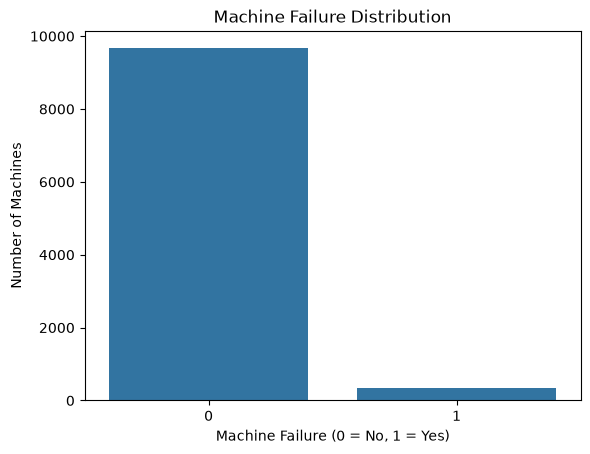

In [31]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count machine failures
print(df["Machine failure"].value_counts())

sns.countplot(data=df, x="Machine failure")
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")
plt.show()


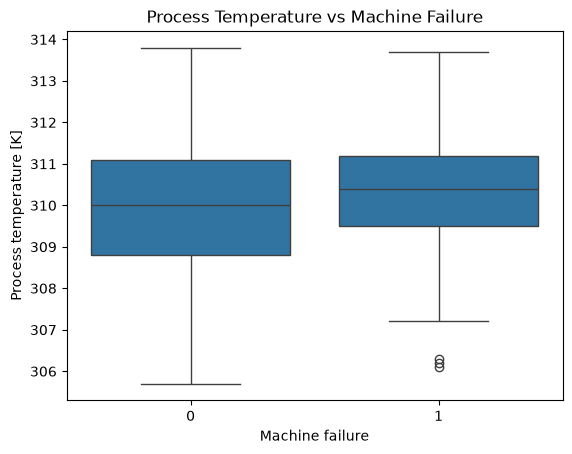

In [32]:
sns.boxplot(
    data=df,
    x="Machine failure",
    y="Process temperature [K]"
)
plt.title("Process Temperature vs Machine Failure")
plt.show()


In [35]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the Kaggle dataset
df = pd.read_csv("data/archive/ai4i2020.csv")


In [36]:
# Select input features and target
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 8000
Testing records: 2000


In [37]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 98.0 %

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71      0.69      0.70        68

    accuracy                           0.98      2000
   macro avg       0.85      0.84      0.85      2000
weighted avg       0.98      0.98      0.98      2000



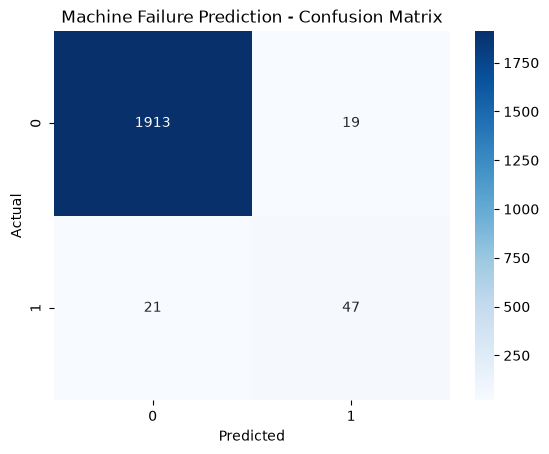

In [38]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Machine Failure Prediction - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [39]:
import os
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump(model, "models/machine_failure_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [40]:
import pandas as pd
from pathlib import Path

# Use the dataset already loaded in df
clean_df = df.copy()

# Remove exact duplicate rows, if any
duplicates_before = clean_df.duplicated().sum()
clean_df = clean_df.drop_duplicates().copy()

# Check missing values
missing_values = clean_df.isnull().sum()

# Check data types
print("Original rows:", len(df))
print("Duplicate rows removed:", duplicates_before)
print("Rows after duplicate removal:", len(clean_df))
print("\nMissing values by column:")
print(missing_values)
print("\nData types:")
print(clean_df.dtypes)

# Save the cleaned dataset
output_folder = Path("data archive")
output_folder.mkdir(exist_ok=True)
output_path = output_folder / "ai4i2020_cleaned.csv"
clean_df.to_csv(output_path, index=False)

print("\nCleaned dataset saved to:", output_path)
print("Final shape:", clean_df.shape)

Original rows: 10000
Duplicate rows removed: 0
Rows after duplicate removal: 10000

Missing values by column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF